# Real-space overlap is not enough: ambiguity in nanobeam iterative ptychography

**Scan 24: Direct and iterative reconstruction**

**Authors:** Stephanie M. Ribet, Mohsen Danaie, Willem P.M. de Kleijne, Arthur R. C. McCray, Frederick Allars, Christopher S. Allen, Colin Ophus, Georgios Varnavides

**Affiliations:**
- National Center for Electron Microscopy, Molecular Foundry, Lawrence Berkeley National Laboratory
- Electron Physical Sciences Imaging Centre, Diamond Light Source
- Department of Imaging Physics, Delft University of Technology
- Department of Materials Science and Engineering, Stanford University

In [1]:
%load_ext autoreload 
%autoreload 2

In [2]:
import numpy as np

import quantem as em
from quantem.core import config
from quantem.core.visualization import show_2d
import matplotlib.pyplot as plt

# load data

In [3]:
probe_semiangle = 1.5
energy = 300e3

In [4]:
dirpath = ""
filepath_data = dirpath + "nanobeam_ptycho_27_master.h5"
dc = em.io.read_4dstem(filepath_data, file_type="arina")
print(dc)

quantem Dataset named '4D-STEM dataset'
  shape: (512, 512, 192, 192)
  dtype: uint16
  device: cpu
  origin: [0. 0. 0. 0.]
  sampling: [0.47470101 0.47470101 1.         1.        ]
  units: ['A', 'A', 'pixels', 'pixels']
  signal units: 'arb. units'


In [5]:
dc.bin(2, axes= (2,3), modify_in_place=True)

# calibrate

In [6]:
dc.get_dp_mean()

Dataset(shape=(96, 96), dtype=float64, name='4D-STEM dataset_dp_mean')
  sampling: [2. 2.]
  units: ['pixels', 'pixels']
  signal units: 'arb. units'

(<Figure size 1200x400 with 3 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >], dtype=object))

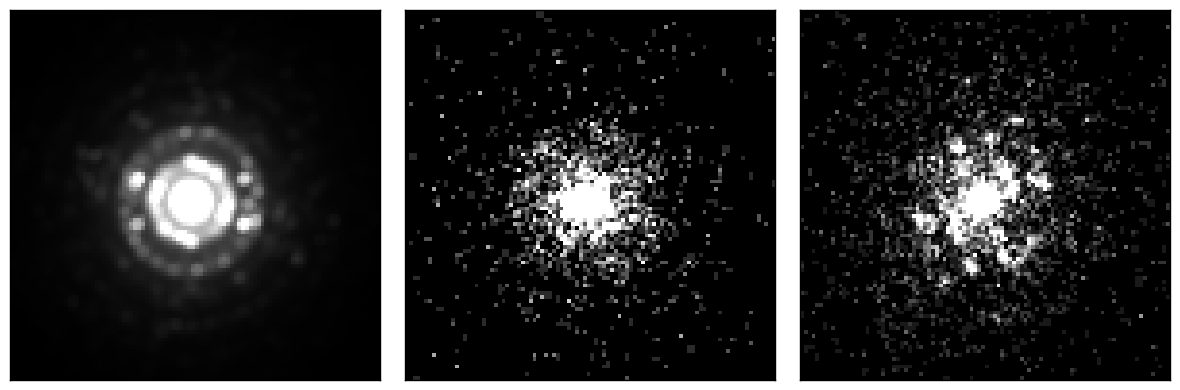

In [7]:
em.visualization.show_2d(
    [
        dc.dp_mean,
        dc.array[128,128],
        dc.array[256,256]
    ]
)

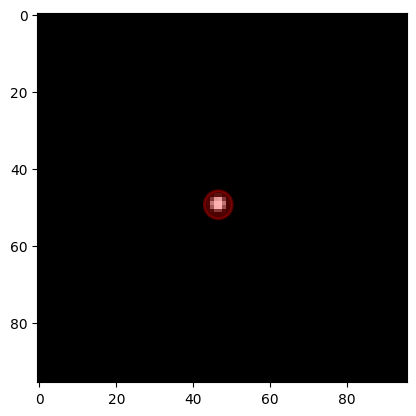

quantem Dataset named '4D-STEM dataset'
  shape: (512, 512, 96, 96)
  dtype: uint64
  device: cpu
  origin: [0.  0.  0.5 0.5]
  sampling: [0.47470101 0.47470101 0.93246184 0.93246184]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'


In [8]:
from quantem.core.utils.diffractive_imaging_utils import fit_probe_circle
probe_qy0, probe_qx0, probe_R = fit_probe_circle(dc.dp_mean.array, show=True)
dc.sampling[2] = 0.93246184
dc.sampling[3] = 0.93246184
dc.units[2:] = ["mrad", "mrad"]

print(dc)

# direct ptycho

In [9]:
import gc
import torch 

torch.cuda.empty_cache()
gc.collect()

3060

  0%|          | 0/50 [00:00<?, ?it/s]

Optimized state:

 HyperparameterState(
  initial_aberrations={'C10': -200.0},
  initial_rotation_angle_deg=-169,
  optimized_aberrations={'C10': -4972.5526374207175, 'C12': 35.3278559098221, 'phi12': 0.041924051633952575},
)
Reconstructing with:

 HyperparameterState(
  current_aberrations={'C10': -4972.5526374207175, 'C12': 35.3278559098221, 'phi12': 0.041924051633952575},
  current_rotation_angle_deg=-169,
)


  0%|          | 0/9 [00:00<?, ?it/s]

(<Figure size 400x400 with 1 Axes>, <Axes: >)

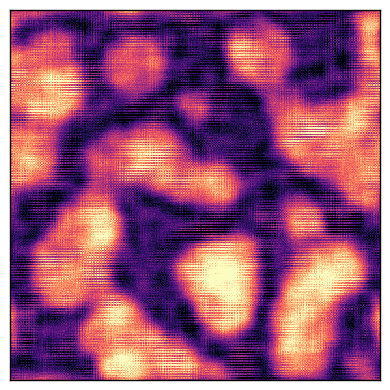

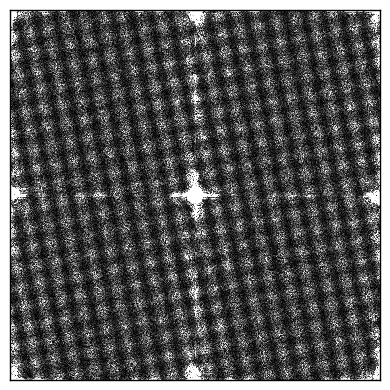

In [10]:
direct_ptycho = em.diffractive_imaging.direct_ptychography.DirectPtychography.from_dataset4d(
    dc,
    energy=energy,
    semiangle_cutoff=probe_semiangle,
    aberration_coefs={
        "C10":-200
    },
    device="gpu",
    rotation_angle=-169, 
    max_batch_size=32
)


from quantem.diffractive_imaging.direct_ptychography import OptimizationParameter
direct_ptycho.optimize_hyperparameters(
    aberration_coefs={
        "C10":OptimizationParameter(-6000,400),
        "C12":OptimizationParameter(0, 50),
        "phi12":OptimizationParameter(-np.pi/2, np.pi/2)
    },
    deconvolution_kernel='parallax',
)



direct_ptycho.reconstruct(
    upsampling_factor = 2,
    deconvolution_kernel='parallax',
    max_batch_size = 10
)

show_2d(direct_ptycho.obj, cmap = "magma")


show_2d(np.fft.fftshift(np.abs(np.fft.fft2(direct_ptycho.obj))))

In [12]:
import h5py
with h5py.File('recons/260704_scan_27_direct_ptycho.h5', 'w') as f:
    f.create_dataset('obj', data = direct_ptycho.obj)
    f.create_dataset('sampling', data = direct_ptycho.sampling)

# iterative ptycho

In [13]:
from quantem.core.datastructures import Dataset4dstem
from quantem.diffractive_imaging.dataset_models import PtychographyDatasetRaster
from quantem.diffractive_imaging.ptychography_lite import PtychoLite, PtychoLiteDIP

Forcing best fit rotation to -169 degrees.
Forcing transpose of intensities to False.


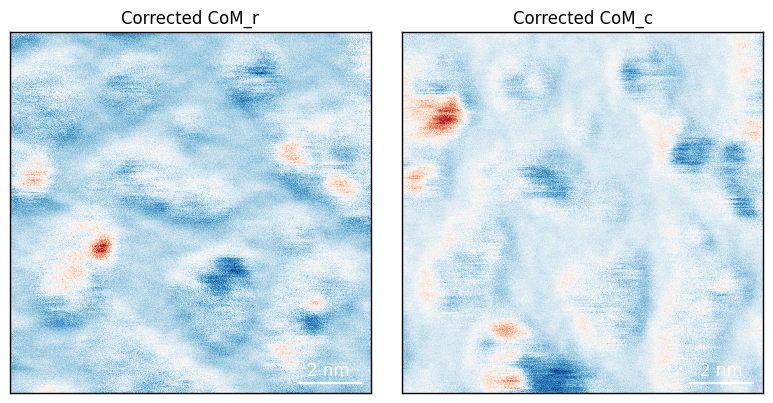

Normalizing intensities:   0%|          | 0/262144 [00:00<?, ?probe position/s]

In [14]:
pdset = PtychographyDatasetRaster.from_dataset4dstem(dc)

pdset.preprocess(
    com_fit_function="constant",
    plot_rotation=True,
    plot_com=True,
    probe_energy=energy,
    force_com_rotation=-169,
    force_com_transpose = False,
)

In [15]:
ptycho_pix = PtychoLite.from_dataset(
    dset=pdset,
    num_slices=1,
    obj_type="complex",
    num_probes=4,
    energy=energy,
    semiangle_cutoff=probe_semiangle,
    obj_padding_px=(32,32),
    device="cpu",
    polar_parameters = {
        'C10': -4972.5526374207175, 'C12': 35.3278559098221, 'phi12': 0.041924051633952575
        
    },
)

Iter 50/50, Loss: 5.866e+03: 100%|█████████████| 50/50 [04:16<00:00,  5.12s/it]


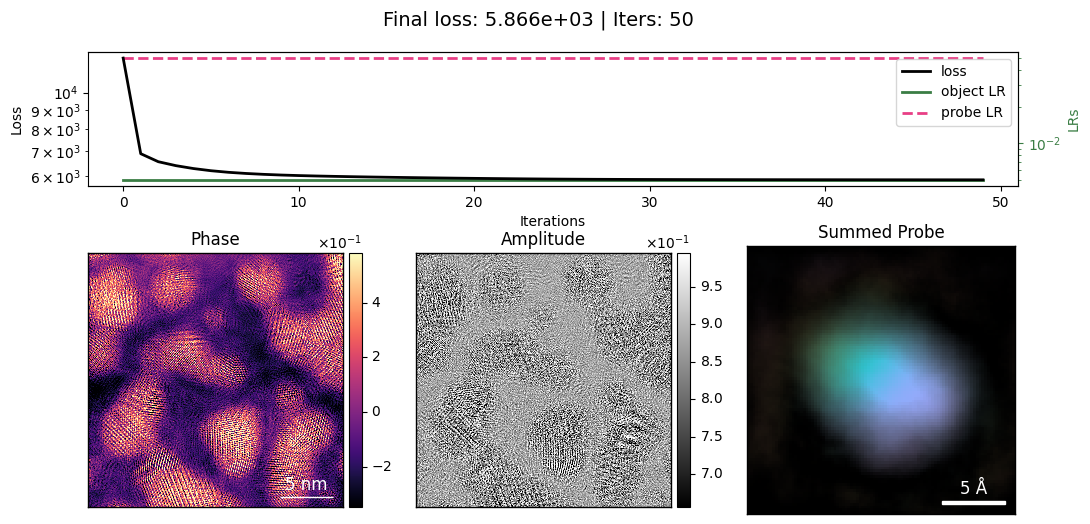

In [16]:
constraints = {
    "object":{
        "identical_slices": True,
    },
    "probe":{
         "orthogonalize_probe": False
    },
}
ptycho_pix.reconstruct(
    num_iters=50, 
    device=[0,1,2], 
    batch_size=512 * 3,
    constraints=constraints,
    reset = True,
    lr_obj = 5e-3,
    lr_probe = 5e-2,
).visualize()

In [17]:
with h5py.File('recons/260704_scan_27_pix_ptycho.h5', 'w') as f:
    f.create_dataset('obj', data = ptycho_pix.obj_cropped)
    f.create_dataset('sampling', data = ptycho_pix.sampling)
    f.create_dataset('probe', data = ptycho_pix.probe)

(<Figure size 800x400 with 2 Axes>, array([<Axes: >, <Axes: >], dtype=object))

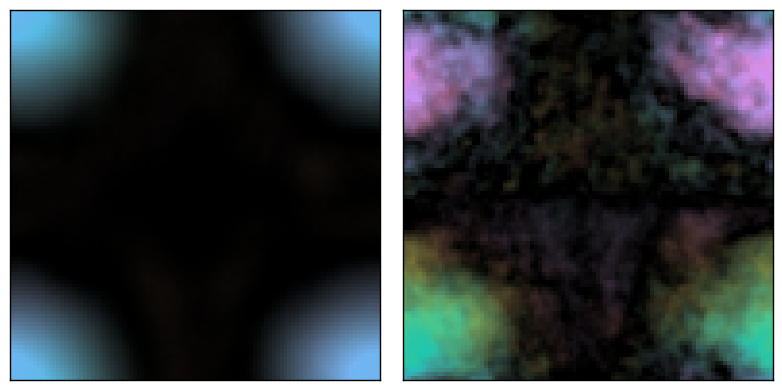

In [26]:
em.visualization.show_2d(
    [
        ptycho_pix.probe[0],
        ptycho_pix.probe[3]
    ]
)

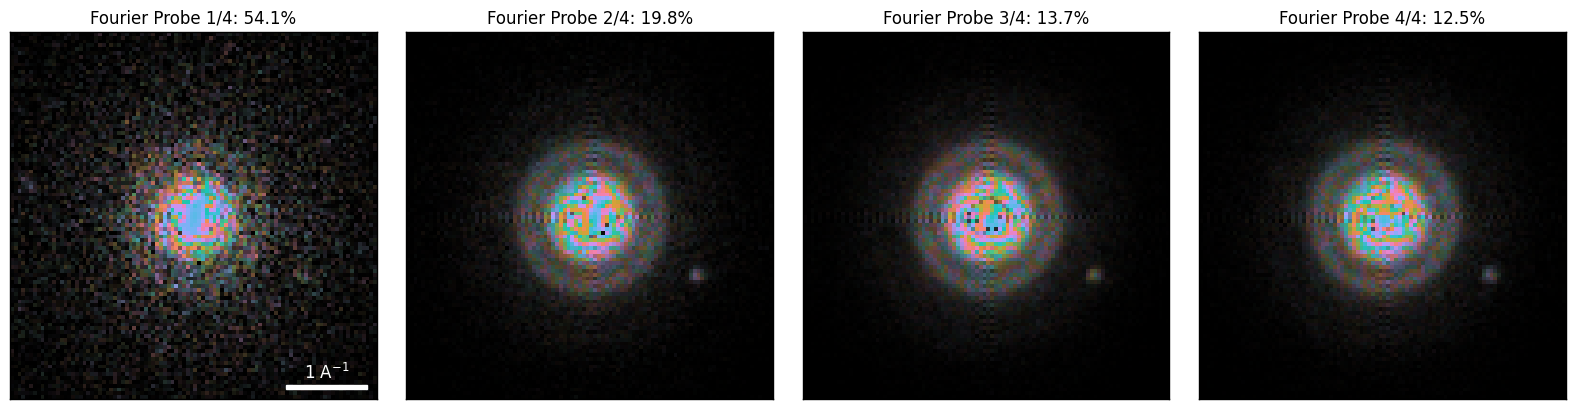

In [28]:
ptycho_pix.show_fourier_probe()

Running reconstruction 1/3 with seed 67


Iter 50/50, Loss: 5.866e+03: 100%|█████████████| 50/50 [04:16<00:00,  5.13s/it]


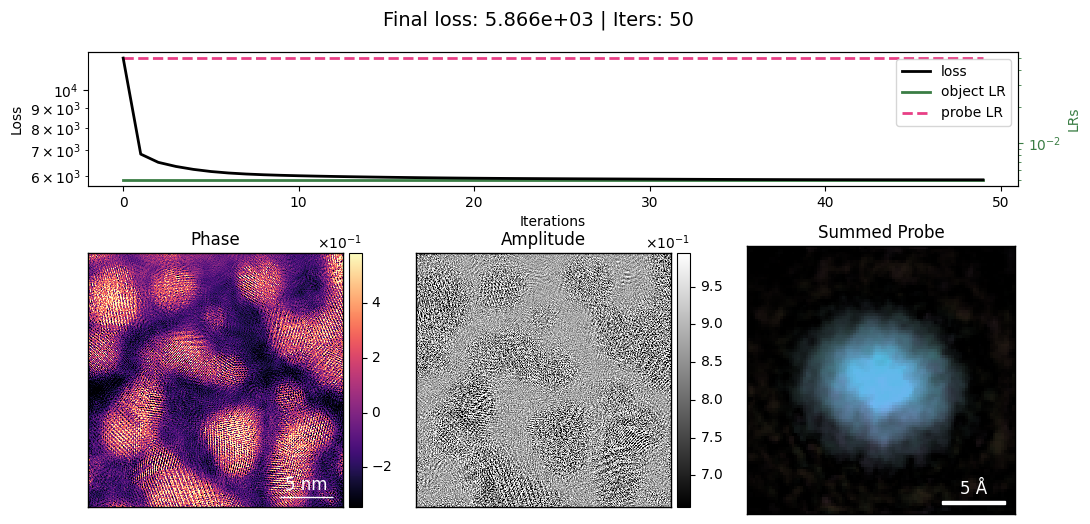

Saved recons/260706_scan_27_pix_ptycho_seed_67.h5
Running reconstruction 2/3 with seed 72


Iter 50/50, Loss: 5.865e+03: 100%|█████████████| 50/50 [04:17<00:00,  5.14s/it]


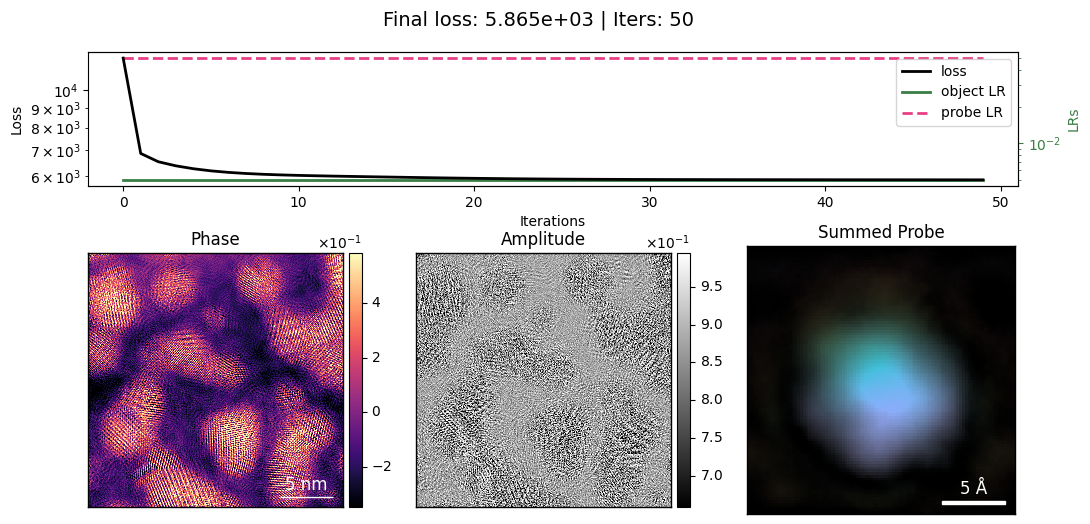

Saved recons/260706_scan_27_pix_ptycho_seed_72.h5
Running reconstruction 3/3 with seed 92


In [ ]:
import os
import random
import numpy as np
import torch
import h5py

os.makedirs("recons", exist_ok=True)

seeds = [67, 72, 92]

constraints = {
    "object": {
        "identical_slices": True,
    },
    "probe": {
        "orthogonalize_probe": False,
    },
}

for run_idx, seed in enumerate(seeds):
    print(f"Running reconstruction {run_idx + 1}/3 with seed {seed}")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    ptycho_pix = PtychoLite.from_dataset(
        dset=pdset,
        num_slices=1,
        obj_type="complex",
        num_probes=4,
        energy=energy,
        semiangle_cutoff=probe_semiangle,
        obj_padding_px=(32, 32),
        device="cpu",
        polar_parameters={
            "C10": -4972.5526374207175,
            "C12": 35.3278559098221,
            "phi12": 0.041924051633952575,
        },
    )

    ptycho_pix.reconstruct(
        num_iters=50,
        device=[0, 1, 2],
        batch_size=512 * 3,
        constraints=constraints,
        reset=True,
        lr_obj=5e-3,
        lr_probe=5e-2,
    ).visualize()

    out_path = f"recons/260706_scan_27_pix_ptycho_seed_{seed}.h5"
    with h5py.File(out_path, "w") as f:
        f.attrs["seed"] = seed
        f.attrs["run_idx"] = run_idx
        f.create_dataset("obj", data=ptycho_pix.obj_cropped)
        f.create_dataset("sampling", data=ptycho_pix.sampling)
        f.create_dataset("probe", data=ptycho_pix.probe)

    print(f"Saved {out_path}")